### Experiment notes — 1

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 2

Introduction and motivation for the analysis. Assignment scope and evaluation requirements. Key techniques: Bagging, AdaBoost, SVM, AUC, roc, k-NN.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 3

Project goals and evaluation criteria. Dataset provenance, format and train/test split. Key techniques: Naive Bayes, Logistic Regression, TF-IDF, Bagging, AUC, AdaBoost, SVM, K-nn.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*
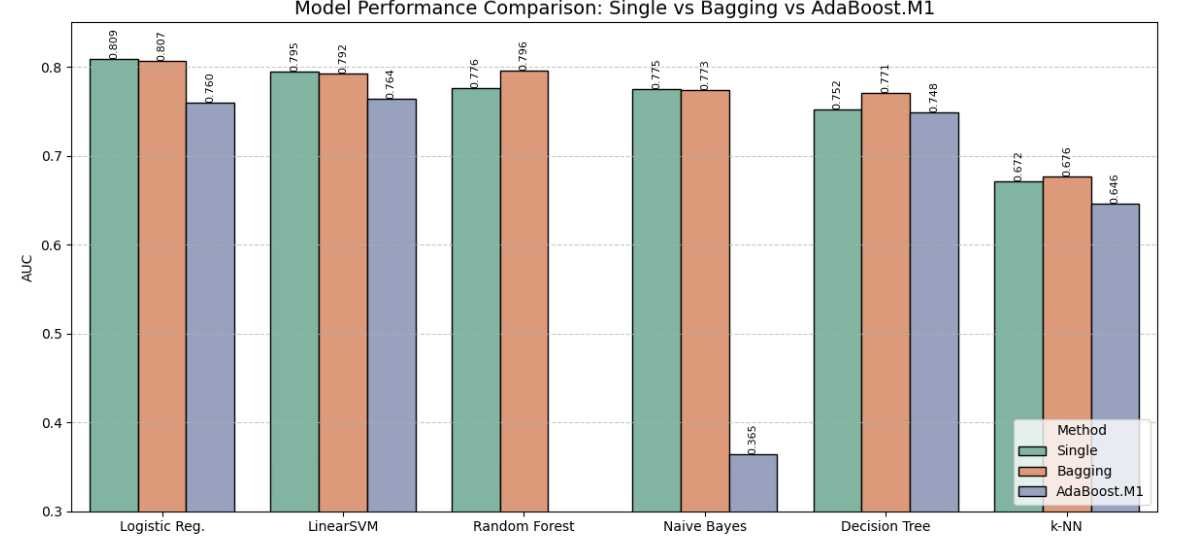

### Experiment notes — 4

Dataset overview and problem setup.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [1]:
import pandas as pd 
train_df = pd.read_csv('./data/train.csv', sep='\t')

In [2]:
test_df = pd.read_csv('./data/test.csv', sep='\t')

In [3]:
ground_truth = pd.read_csv("./data/groundTruth.csv",sep=',') # test set label

In [4]:
train_df

,reviewerID,asin,reviewText,overall,votes_up,votes_all,label
0,7885,3901,"First off, allow me to correct a common mistak...",5.0,6,7,0
1,52087,47978,I am really troubled by this Story and Enterta...,3.0,99,134,0
2,5701,3667,A near-perfect film version of a downright glo...,4.0,14,14,1
3,47191,40892,Keep your expectations low. Really really low...,1.0,4,7,0
4,40957,15367,"""they dont make em like this no more...""well.....",5.0,3,6,0
...,...,...,...,...,...,...,...
57034,58315,29374,"If you like beautifully shot, well acted films...",2.0,12,21,0
57035,23328,45548,This is a great set of films Wayne did Fox and...,5.0,15,18,0
57036,27203,42453,It's what's known as a comedy of manners. It's...,3.0,4,5,0
57037,33992,44891,Ellen can do no wrong as far a creating wonder...,5.0,4,5,0


In [5]:
test_df

,Id,reviewerID,asin,reviewText,overall
0,0,82947,37386,I REALLY wanted this series but I am in SHOCK ...,1.0
1,1,10154,23543,I have to say that this is a work of art for m...,4.0
2,2,5789,5724,Alien 3 is certainly the most controversal fil...,3.0
3,3,9198,5909,"I love this film...preachy? Well, of course i...",5.0
4,4,33252,21214,Even though I previously bought the Gamera Dou...,5.0
...,...,...,...,...,...
11203,11203,18250,35309,I honestly never heard of the graphic novel un...,5.0
11204,11204,3200,2130,Archie Bunker's command to stifle YOURSELF! wa...,5.0
11205,11205,37366,41971,"In LSD - My Problem Child, Albert Hoffman wrot...",5.0
11206,11206,1781,33089,I have owned this DVD for over a year now and ...,5.0


In [6]:
ground_truth

,Id,Expected
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
...,...,...
11203,11203,0
11204,11204,0
11205,11205,0
11206,11206,0


In [7]:
ground_truth.Expected.value_counts()

Expected
0    9064
1    2144
Name: count, dtype: int64

In [8]:
train_df.label.value_counts()

label
0    44137
1    12902
Name: count, dtype: int64

### Experiment notes — 13

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 14

Inspect and engineer input features.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 15

Prepare features and clean the input dataset.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [7]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, HashingVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, accuracy_score
from joblib import Parallel, delayed # compute
import inspect
import os
import csv
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import re
# base estimator
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [8]:
# ======= =======
train_path = './data/train.csv'
test_path = './data/test.csv'
gt_path = './data/groundTruth.csv' # test set label

val_size = 0.2 # training set validation set ratio
RANDOM_SEED = 42

In [9]:
# 1. data load
def load_raw_data(train_path, test_path, gt_path):
    """
    返回：
        train_df, test_df, gt_df, y_train, y_test
    """
    train_df = pd.read_csv(train_path, sep='\t')
    test_df = pd.read_csv(test_path, sep='\t')
    gt_df = pd.read_csv(gt_path, sep=',')

    # label process
    y_train = train_df['label'].values

    # test set Id
    test_df = test_df.sort_values('Id').reset_index(drop=True)
    gt_df = gt_df.sort_values('Id').reset_index(drop=True)
    assert (test_df['Id'].values == gt_df['Id'].values).all()
    y_test = gt_df['Expected'].values.ravel().astype(int)

    return train_df, test_df, y_train, y_test

In [10]:
# 2. text process
def build_text_processor(method='tfidf', **kwargs):
    """
    根据 method 返回相应的文本向量化器。
    
    Parameters
    ----------
    method : str
        'tfidf' -> TfidfVectorizer
        'count' -> CountVectorizer
        'hash'  -> HashingVectorizer （无词汇表，适合在线学习或大内存）
    kwargs : 对应向量化器的参数
        通用参数：max_features, stop_words, ngram_range, max_df, min_df 等
        HashingVectorizer 专用：n_features （默认2**20）
    """
    method = method.lower()
    common_params = {k: v for k, v in kwargs.items() if k != 'n_features'}
    
    if method == 'tfidf':
        return TfidfVectorizer(**common_params)
    elif method == 'count':
        return CountVectorizer(**common_params)
    elif method == 'hash':
        n_features = kwargs.get('n_features', 2**20)
        # HashingVectorizer stop_words parameters
        hash_params = {
            'n_features': n_features,
            'ngram_range': kwargs.get('ngram_range', (1, 1)),
            'alternate_sign': kwargs.get('alternate_sign', True),
        }
        return HashingVectorizer(**hash_params)
    else:
        raise ValueError(f"Unsupported method: {method}. Choose 'tfidf', 'count', or 'hash'.")


In [11]:
# 3. feature concatenate function
def prepare_features(train_df, test_df, vectorizer, use_overall=True):
    """
    vectorizer: 任何具有 fit_transform/transform 的文本向量化器对象          
    use_overall: 是否拼接评分特征
    分别处理reviewText和overall列
    - vectorizer=None 表示不做文本向量化，即不考虑该特征
    - use_overall=False 表示不包括评分特征
    """
    if vectorizer is not None:
        X_text_train = vectorizer.fit_transform(train_df['reviewText'])
        X_text_test = vectorizer.transform(test_df['reviewText'])
    else:
        X_text_train = sp.csr_matrix((train_df.shape[0], 0))
        X_text_test = sp.csr_matrix((test_df.shape[0], 0))

    if use_overall:
        overall_train = (train_df['overall'].values / 5.0).reshape(-1, 1)
        overall_test = (test_df['overall'].values / 5.0).reshape(-1, 1)
        X_train = sp.hstack([X_text_train, overall_train]).tocsr()
        X_test = sp.hstack([X_text_test, overall_test]).tocsr()
    else:
        X_train, X_test = X_text_train.tocsr(), X_text_test.tocsr()
    return X_train, X_test

In [12]:
print("正在加载数据...")
train_df, test_df, y_train, y_test = load_raw_data(train_path, test_path, gt_path)

tfidf_vec = build_text_processor(method='tfidf', max_features=5000, stop_words='english')
X_train, X_test = prepare_features(train_df, test_df, vectorizer=tfidf_vec, use_overall=True)

print(f"训练集大小: {X_train.shape[0]}")
print(f"测试集大小: {y_test.shape[0]}")
print(f"特征维度: {X_train.shape[1]}")

正在加载数据...
训练集大小: 57039
测试集大小: 11208
特征维度: 5001


In [28]:
# inspect 0 sample text feature and overall feature concatenate
print("评分特征值:", X_train[0, -1])          # last one
print("文本最后10个词频/重要性:", X_train[0, -10:].toarray())   # last 10 feature

评分特征值: 1.0
文本最后10个词频/重要性: [[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [35]:
y_train

array([0, 0, 1, ..., 0, 0, 1], shape=(57039,))

In [36]:
y_test

array([0, 0, 0, ..., 0, 0, 0], shape=(11208,))

In [32]:
# asin,reviewerID
has_duplicates = train_df['asin'].duplicated().any()
print(f"是否有重复: {has_duplicates}")
counts = train_df['asin'].value_counts()
print(counts[counts > 1])   # only display 1ID

是否有重复: True
asin
10       113
13627    110
1907     101
13561     93
13495     87
        ... 
32584      2
49329      2
12868      2
18272      2
12986      2
Name: count, Length: 10322, dtype: int64


In [33]:
# one user one ？
combo_counts = train_df.groupby(['reviewerID', 'asin']).size().reset_index(name='count')
# filter >1
duplicate_combos = combo_counts[combo_counts['count'] > 1]
print(duplicate_combos)

Empty DataFrame
Columns: [reviewerID, asin, count]
Index: []


In [34]:
combo_counts_test = test_df.groupby(['reviewerID', 'asin']).size().reset_index(name='count')
# filter >1
duplicate_combos_test = combo_counts_test[combo_counts_test['count'] > 1]
print(duplicate_combos_test)

Empty DataFrame
Columns: [reviewerID, asin, count]
Index: []


### Experiment notes — 28

Interpretation of results and model behavior. Fit models and inspect generalization.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 29

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [7]:
# Bagging
class ManualBaggingClassifier(BaseEstimator, ClassifierMixin):
    """
    手动实现Bagging，支持并行计算
    输入：支持稀疏矩阵输入；基分类器必须支持概率输出
    输出：平均概率进行预测
    """
    def __init__(self, base_estimator=None, n_estimators=10, random_state=None, max_samples=1.0, n_jobs=1, 
                 bootstrap=True):
        self.base_estimator = base_estimator
        self.n_estimators = n_estimators    # model
        self.max_samples = max_samples      # from X take sample ratio
        self.bootstrap = bootstrap          # True
        self.random_state = random_state    # indices one one
        self.n_jobs = n_jobs                # compute ,n_jobs=-1 use all CPU
        self.estimators_ = []
        self.n_classes_ = None              # class

    # Bootstrap generate dataset
    def _bootstrap_sample(self, X, y, rng):
        n_samples = X.shape[0]
        
        # 1. compute sample
        if self.max_samples == 1.0 or self.max_samples is None:
            n_draw = n_samples
        elif isinstance(self.max_samples, float):
            n_draw = int(self.max_samples * n_samples)
        else:
            n_draw = self.max_samples
            
        # 2. bootstrap
        indices = rng.choice(n_samples, size=n_draw, replace=self.bootstrap)
        
        # sparse matrix ， CSR （ sparse matrix
        X_sub = X[indices]
        if sp.issparse(X_sub):
            X_sub = X_sub.tocsr()
        # y Pandas Series， for numpy
        if hasattr(y, 'iloc'):
            y_sub = y.iloc[indices].values
        else:
            y_sub = y[indices]
        return X_sub, y_sub

    # training single function
    def _fit_estimator(self, seed, X, y):
        rng = np.random.RandomState(seed)
        estimator = clone(self.base_estimator)  # base estimator
        X_sample, y_sample = self._bootstrap_sample(X, y, rng)
        estimator.fit(X_sample, y_sample)
        return estimator
    
    # prediction single function
    def _predict_proba_estimator(self, est, X):
        return est.predict_proba(X)
    
    def fit(self, X, y):
        # generate ， one
        self._rng = np.random.RandomState(self.random_state)
        self.n_classes_ = len(np.unique(y))
        seeds = self._rng.randint(0, np.iinfo(np.int32).max, size=self.n_estimators)

        if self.n_jobs == 1:
            # retain for
            self.estimators_ = []
            for i in range(self.n_estimators):
                self.estimators_.append(self._fit_estimator(seeds[i], X, y))
        else:
            # training all
            self.estimators_ = Parallel(n_jobs=self.n_jobs)(
                delayed(self._fit_estimator)(seed, X, y) for seed in seeds
            )
        return self

    def predict_proba(self, X):
        """
        对每个基分类器的概率输出求平均，得到最终概率
        """
        if not self.estimators_:
            raise RuntimeError("模型尚未训练")
            
        if self.n_jobs == 1:
            avg_proba = np.zeros((X.shape[0], self.n_classes_))
            for est in self.estimators_:
                avg_proba += est.predict_proba(X)
            avg_proba /= len(self.estimators_)
            return avg_proba
        else:
            # prediction each ， last merge probability
            probas = Parallel(n_jobs=self.n_jobs)(
                delayed(self._predict_proba_estimator)(est, X) for est in self.estimators_
            )
            avg_proba = np.sum(probas, axis=0) / len(self.estimators_)
            return avg_proba

    def predict(self, X):
        avg_proba = self.predict_proba(X)
        return np.argmax(avg_proba, axis=1)

In [8]:
class ManualAdaBoostM1Classifier(BaseEstimator, ClassifierMixin):
    """
    手动实现 AdaBoost.M1（二分类），算法：
    - 错误率 = 所有错误分类样本权重和
    - 若错误率 > 0.5 则退出迭代
    - 正确分类样本权重乘以 beta_t = error/(1-error)
    - 最终融合权重 alpha_t = log(1/beta_t)
    AUC 评价：本文使用加权概率平均 / 或加权正类投票分数作为连续 score
    参考Sklearn加入学习率 learning_rate 调整投票权重
    考虑基模型是否使用sample_weight，若不支持则加权重采样 
    """
    def __init__(self, base_estimator=None, n_estimators=50, random_state=None, learning_rate=1.0, n_jobs=1):
        self.base_estimator = base_estimator
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.learning_rate = learning_rate   # learning_rate < 1.0 ， model weights
        self.estimators_ = []
        self.estimator_weights_ = []
        self.n_jobs = n_jobs              # * prediction * compute
        self.classes_ = None

    def fit(self, X, y):
        self.estimators_ = []
        self.estimator_weights_ = []
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError("AdaBoost.M1 as described is for binary classification only.")
        
        n_samples = X.shape[0]
        rng = np.random.RandomState(self.random_state)
        
        # initialize sample weights
        sample_weights = np.ones(n_samples) / n_samples

        for _ in range(self.n_estimators):
            estimator = clone(self.base_estimator)

            # for base estimator add
            if hasattr(estimator, 'random_state'):
                estimator.random_state = rng.randint(0, 100000)
            
            # use sample weights training
            # attempt use sample_weight， weights
            if 'sample_weight' in inspect.signature(estimator.fit).parameters:
                estimator.fit(X, y, sample_weight=sample_weights)
            else:
                n_samples = len(y)
                # weights
                indices = rng.choice(
                        np.arange(n_samples), size=n_samples, replace=True, p=sample_weights
                    )
                estimator.fit(X[indices], y[indices])
            
            y_pred = estimator.predict(X)

            # compute ： all classification sample weights and
            incorrect = (y_pred != y)
            error = np.sum(sample_weights[incorrect])

            # > 0.5，， loop
            if error > 0.5:
                break
            
            # for 0， model ， weights
            if error == 0:
                alpha = self.learning_rate * 10.0  # one value table log(1/0)
                self.estimators_.append(estimator)
                self.estimator_weights_.append(alpha)
                break

            beta = error / (1.0 - error)
            
            # sample weights ： classification beta， classification
            sample_weights[~incorrect] *= beta
            # normalization
            sample_weights /= np.sum(sample_weights)

            # weights alpha_t = log(1/beta)
            alpha = self.learning_rate * np.log(1.0 / beta)
            self.estimators_.append(estimator)
            self.estimator_weights_.append(alpha)

        return self

    # function
    @staticmethod
    def _predict_one(est, X):
        return est.predict_proba(X)
    
    def predict_proba(self, X):
        if not self.estimators_:
            raise RuntimeError("模型尚未训练或所有弱学习器均不满足条件")
        
        # compute each probability output
        if self.n_jobs == 1:
            probas = [est.predict_proba(X) for est in self.estimators_]
        else:
            probas = Parallel(n_jobs=self.n_jobs)(
                delayed(ManualAdaBoostM1Classifier._predict_one)(est, X)
                for est in self.estimators_
            )
        
        # and
        total_weight = sum(self.estimator_weights_)
        weighted_sum = np.zeros((X.shape[0], len(self.classes_)))
        for alpha, proba in zip(self.estimator_weights_, probas):
            weighted_sum += alpha * proba
        
        return weighted_sum / total_weight

    def predict(self, X):
        proba = self.predict_proba(X)
        return self.classes_[np.argmax(proba, axis=1)]

### Experiment notes — 32

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [9]:
def evaluate_model(model, X_train, y_train, X_test, y_test, calibrate_random_state=42):
    # model predict_proba， classification
    if not hasattr(model, "predict_proba"):
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=calibrate_random_state)
        model = CalibratedClassifierCV(model, cv=cv, method='sigmoid')
    
    model.fit(X_train, y_train)
    # one use probability prediction （ two classification
    y_scores = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_scores)
    return auc

In [10]:
# build probability output base estimator
def make_calibrated_linearsvc(random_state):
    svm = LinearSVC(random_state=random_state, dual=False, max_iter=1000, tol=1e-3)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)
    return CalibratedClassifierCV(svm, cv=cv, method='sigmoid')
    
# model 🆚 4 model
base_models = {
    "Single Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_SEED),
    "Single Calibrated LinearSVC": LinearSVC(random_state=RANDOM_SEED, dual=False, max_iter=1000, tol=1e-3),
    # model
    "Single k-NN": KNeighborsClassifier(metric='cosine', n_neighbors=10, n_jobs=-1),
    "Single NaiveBayes": MultinomialNB(alpha=0.1),
    "Single LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
    "Single RandomForest": RandomForestClassifier(n_estimators=50, random_state=RANDOM_SEED)
}

models = {
        "Bagging + DecisionTree": ManualBaggingClassifier(base_estimator=DecisionTreeClassifier(max_depth=10, random_state=RANDOM_SEED), n_estimators=10, random_state=RANDOM_SEED, n_jobs=-1),
        "Bagging + LinearSVM": ManualBaggingClassifier(base_estimator=make_calibrated_linearsvc(RANDOM_SEED), n_estimators=10, random_state=RANDOM_SEED, n_jobs=-1),
        "AdaBoost.M1 + DecisionTree": ManualAdaBoostM1Classifier(base_estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED), n_estimators=10, random_state=RANDOM_SEED, n_jobs=-1),
        "AdaBoost.M1 + LinearSVM": ManualAdaBoostM1Classifier(base_estimator=make_calibrated_linearsvc(RANDOM_SEED), n_estimators=10, learning_rate=0.8, random_state=RANDOM_SEED, n_jobs=-1)
    }

In [11]:
results = {}
for name, model in base_models.items():
    print(f"\n训练模型: {name}")
    auc = evaluate_model(model, X_train, y_train, X_test, y_test)
    results[name] = auc
    print(f"测试集 AUC: {auc:.4f}")


训练模型: Single Decision Tree
测试集 AUC: 0.7515

训练模型: Single Calibrated LinearSVC
测试集 AUC: 0.7947

训练模型: Single k-NN
测试集 AUC: 0.6717

训练模型: Single NaiveBayes
测试集 AUC: 0.7745

训练模型: Single LogisticRegression
测试集 AUC: 0.8085

训练模型: Single RandomForest
测试集 AUC: 0.7758


In [12]:
import gc
gc.collect()

323

In [13]:
for name, model in models.items():
    print(f"\n训练模型: {name}")
    auc = evaluate_model(model, X_train, y_train, X_test, y_test)
    results[name] = auc
    print(f"测试集 AUC: {auc:.4f}")


训练模型: Bagging + DecisionTree
测试集 AUC: 0.7709

训练模型: Bagging + LinearSVM
测试集 AUC: 0.7920

训练模型: AdaBoost.M1 + DecisionTree
测试集 AUC: 0.7483

训练模型: AdaBoost.M1 + LinearSVM
测试集 AUC: 0.7642


In [14]:
# output comparison results
print("\n" + "="*50)
print("模型性能对比 (测试集 AUC):")
for name, auc in results.items():
    print(f"{name}: {auc:.4f}")


模型性能对比 (测试集 AUC):
Single Decision Tree: 0.7515
Single Calibrated LinearSVC: 0.7947
Single k-NN: 0.6717
Single NaiveBayes: 0.7745
Single LogisticRegression: 0.8085
Single RandomForest: 0.7758
Bagging + DecisionTree: 0.7709
Bagging + LinearSVM: 0.7920
AdaBoost.M1 + DecisionTree: 0.7483
AdaBoost.M1 + LinearSVM: 0.7642


In [15]:
# output results to csv
file_exists = os.path.isfile('model_results.csv')
with open('model_results.csv', 'a', newline='', encoding='utf-8-sig') as f:
    writer = csv.writer(f)
    if not file_exists:          # file table
        writer.writerow(['Model', 'AUC'])
    for name, auc in results.items():
        writer.writerow([name, auc])

### Experiment notes — 40

Additional experiments and alternative baselines. Key techniques: k-NN.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [11]:
# base estimator （ base estimator parameters
def create_base_knn():
    """k-NN 设定距离度量、邻居数"""
    return KNeighborsClassifier(metric='cosine', n_neighbors=10)

def create_base_nb():
    """
    由于GaussianNB要求输入为密集矩阵且特征近似高斯分布，不适合 TF‑IDF 稀疏文本特征
    此处选择MultinomialNB，适合文本特征，且输出概率稳定
    """
    return MultinomialNB(alpha=0.1) # parameters ， from probability for 0

def create_base_logreg():
    """逻辑回归，设置：最大最大迭代数"""
    return LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)

def create_base_rf():
    """随机森林本身支持 predict_proba，设置：n_estimators 决策树的数量"""
    return RandomForestClassifier(n_estimators=50, random_state=RANDOM_SEED)

# model
# compute 、 model models_more2
models_more1 = {
    "Bagging + k-NN": ManualBaggingClassifier(
        base_estimator=create_base_knn(),
        n_estimators=10, n_jobs=-1, random_state=RANDOM_SEED
    ),
    "Bagging + NaiveBayes": ManualBaggingClassifier(
        base_estimator=create_base_nb(),
        n_estimators=10, n_jobs=-1, random_state=RANDOM_SEED
    ),
    "Bagging + LogisticRegression": ManualBaggingClassifier(
        base_estimator=create_base_logreg(),
        n_estimators=10, n_jobs=-1, random_state=RANDOM_SEED
    ),
    "AdaBoost.M1 + NaiveBayes": ManualAdaBoostM1Classifier(
        base_estimator=create_base_nb(),
        n_estimators=10, random_state=RANDOM_SEED, n_jobs=-1
    ),
    "AdaBoost.M1 + LogisticRegression": ManualAdaBoostM1Classifier(
        base_estimator=create_base_logreg(),
        n_estimators=10, learning_rate=0.8, random_state=RANDOM_SEED, n_jobs=-1
    ),
    "Bagging + RandomForest": ManualBaggingClassifier(
        base_estimator=create_base_rf(),
        n_estimators=10, n_jobs=-1, random_state=RANDOM_SEED
    )
}

models_more2 = {
    "AdaBoost.M1 + k-NN": ManualAdaBoostM1Classifier(
        base_estimator=create_base_knn(),
        n_estimators=10, random_state=RANDOM_SEED, n_jobs=-1
    )
}

In [13]:
gc.collect()

538

In [18]:
results_more = {}
for name, model in models_more1.items():
    print(f"\n训练模型: {name}")
    auc = evaluate_model(model, X_train, y_train, X_test, y_test)
    results_more[name] = auc
    print(f"测试集 AUC: {auc:.4f}")


训练模型: Bagging + k-NN
测试集 AUC: 0.6764

训练模型: Bagging + NaiveBayes
测试集 AUC: 0.7734

训练模型: Bagging + LogisticRegression
测试集 AUC: 0.8067

训练模型: AdaBoost.M1 + NaiveBayes
测试集 AUC: 0.3645

训练模型: AdaBoost.M1 + LogisticRegression
测试集 AUC: 0.7595

训练模型: Bagging + RandomForest
测试集 AUC: 0.7960


In [19]:
gc.collect()

31

In [14]:
results_more = {}
for name, model in models_more2.items():
    print(f"\n训练模型: {name}")
    auc = evaluate_model(model, X_train, y_train, X_test, y_test)
    results_more[name] = auc
    print(f"测试集 AUC: {auc:.4f}")


训练模型: AdaBoost.M1 + k-NN
测试集 AUC: 0.6459


In [24]:
# output comparison results
print("\n" + "="*50)
print("全部模型性能对比 (测试集 AUC):")

total_results = results | results_more
for name, auc in total_results.items():
    print(f"{name}: {auc:.4f}")


全部模型性能对比 (测试集 AUC):
Single Decision Tree: 0.7515
Single Calibrated LinearSVC: 0.7947
Single k-NN: 0.6717
Single NaiveBayes: 0.7745
Single LogisticRegression: 0.8085
Single RandomForest: 0.7758
Bagging + DecisionTree: 0.7709
Bagging + LinearSVM: 0.7920
AdaBoost.M1 + DecisionTree: 0.7483
AdaBoost.M1 + LinearSVM: 0.7642
Bagging + k-NN: 0.6764
Bagging + NaiveBayes: 0.7734
Bagging + LogisticRegression: 0.8067
AdaBoost.M1 + NaiveBayes: 0.3645
AdaBoost.M1 + LogisticRegression: 0.7595
Bagging + RandomForest: 0.7960


In [17]:
file_exists = os.path.isfile('model_results.csv')
with open('model_results.csv', 'a', newline='', encoding='utf-8-sig') as f:
    writer = csv.writer(f)
    if not file_exists:          # file table
        writer.writerow(['Model', 'AUC'])
    for name, auc in results_more.items():
        writer.writerow([name, auc])

### Experiment notes — 48

Visualize model performance and data distributions. Interpret the reported empirical results.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [13]:
# load csv file results
df_results = pd.read_csv('model_results.csv', encoding='utf-8-sig')
df_results.columns = ['Model', 'AUC']
# Model ： remove and
df_results['Model'] = df_results['Model'].str.replace(r'^\d+\s*', '', regex=True).str.strip()

In [14]:
# experiment results data classification visualization
# 1. take base estimator and method
def classify_model(name):
    """
    返回 (base_learner, method)
    """
    if name.startswith('Single'):
        base = name.replace('Single', '').strip()
        method = 'Single'
    elif name.startswith('Bagging'):
        base = name.replace('Bagging +', '').strip()
        method = 'Bagging'
    elif name.startswith('AdaBoost.M1'):
        base = name.replace('AdaBoost.M1 +', '').strip()
        method = 'AdaBoost.M1'
    else:
        # attempt mode
        base = name
        method = 'Unknown'
    return base, method

df_results[['Base_Learner', 'Method']] = df_results['Model'].apply(
    lambda x: pd.Series(classify_model(x))
)
df_results

,Model,AUC,Base_Learner,Method
0,Single Decision Tree,0.751517,Decision Tree,Single
1,Single Calibrated LinearSVC,0.794746,Calibrated LinearSVC,Single
2,Single k-NN,0.671656,k-NN,Single
3,Single NaiveBayes,0.774509,NaiveBayes,Single
4,Single LogisticRegression,0.808545,LogisticRegression,Single
5,Single RandomForest,0.775834,RandomForest,Single
6,Bagging + DecisionTree,0.770917,DecisionTree,Bagging
7,Bagging + LinearSVM,0.792043,LinearSVM,Bagging
8,AdaBoost.M1 + DecisionTree,0.748313,DecisionTree,AdaBoost.M1
9,AdaBoost.M1 + LinearSVM,0.764231,LinearSVM,AdaBoost.M1


In [17]:
# one base estimator （ LinearSVM、Calibrated LinearSVC one display
name_map = {
    'DecisionTree': 'Decision Tree',
    'Calibrated LinearSVC': 'LinearSVM',
    'LinearSVM': 'LinearSVM',
    'NaiveBayes': 'Naive Bayes',
    'LogisticRegression': 'Logistic Reg.',
    'RandomForest': 'Random Forest',
}
df_results['Base_Learner'] = df_results['Base_Learner'].map(name_map).fillna(df_results['Base_Learner'])

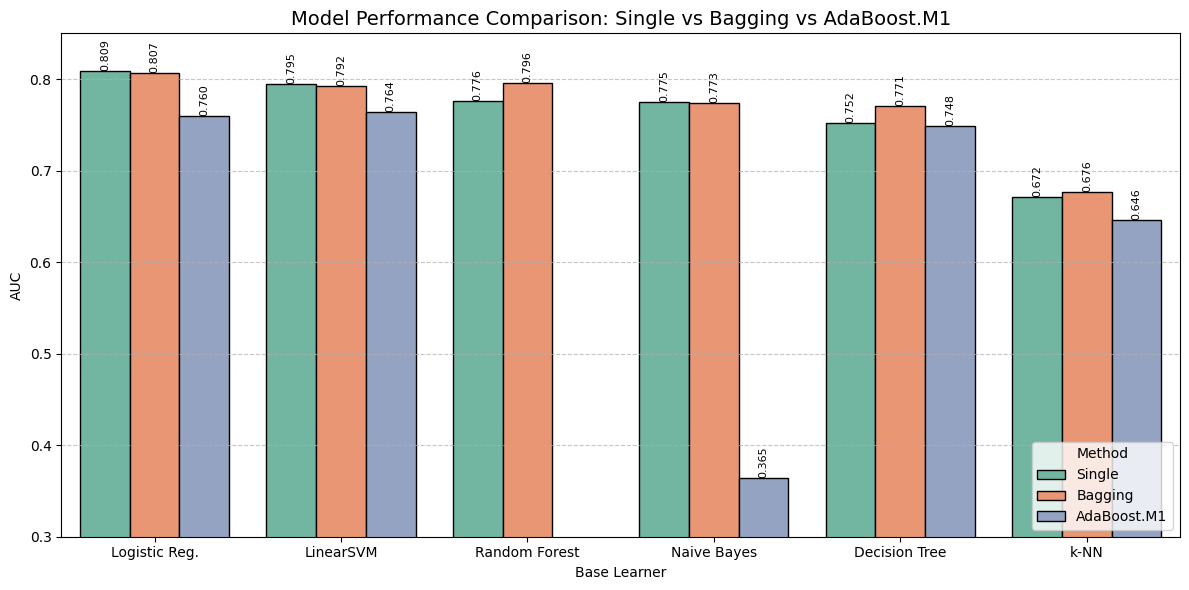

In [19]:
# 2. plot grouped plot
plt.figure(figsize=(12, 6))

# Single model AUC
order = df_results[df_results['Method'] == 'Single'].sort_values('AUC', ascending=False)['Base_Learner']

sns.barplot(
    data=df_results,
    x='Base_Learner',
    y='AUC',
    hue='Method',
    order=order,
    palette='Set2',
    edgecolor='black'
)

plt.title('Model Performance Comparison: Single vs Bagging vs AdaBoost.M1', fontsize=14)
plt.ylabel('AUC')
plt.xlabel('Base Learner')
plt.ylim(0.3, 0.85)  # display AdaBoost+NB
plt.legend(title='Method', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# value
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f'{height:.3f}',
                           (p.get_x() + p.get_width() / 2., height),
                           ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

### Experiment notes — 53

Interpretation of results and model behavior. Inspect and engineer input features. Key techniques: Bagging, AdaBoost.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [20]:
feature_configs = {
    'TF-IDF_5k': {
        'vectorizer': build_text_processor(method='tfidf', max_features=5000, stop_words='english'),
        'use_overall': True
    },
    'TF-IDF_unigram': {
        'vectorizer': build_text_processor(method='tfidf', max_features=8000, ngram_range=(1,1)),
        'use_overall': False         # text ， overall
    },
    'Overall_only': {
        'vectorizer': None,
        'use_overall': True
    },                               # overall， text
    'Count_10k': {
        'vectorizer': build_text_processor(method='count', max_features=10000, stop_words='english'),
        'use_overall': True
    },
    'Hash_2^18': {
        'vectorizer': build_text_processor(method='hash', n_features=2**18, ngram_range=(1,2)),
        'use_overall': True
    }
}

In [21]:
# generate all feature
feature_sets = {}
for name, cfg in feature_configs.items():
    X_tr, X_te = prepare_features(train_df, test_df, cfg['vectorizer'], cfg['use_overall'])
    feature_sets[name] = (X_tr, X_te)

In [23]:
models_exp = {
    "Bagging + DecisionTree": ManualBaggingClassifier(
        base_estimator=DecisionTreeClassifier(max_depth=10, random_state=RANDOM_SEED), 
        n_estimators=10, max_samples=1.0, random_state=RANDOM_SEED, n_jobs=-1),
    "AdaBoost.M1 + DecisionTree": ManualAdaBoostM1Classifier(
        base_estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED), 
        n_estimators=10, learning_rate=0.8, n_jobs=-1, random_state=RANDOM_SEED)    
    }

feature_results = []

for feat_name, (X_train, X_test) in feature_sets.items():
    for model_name, model in models_exp.items():
        print(f"训练模型: {model_name}, 特征配置: {feat_name}")
        auc = evaluate_model(model, X_train, y_train, X_test, y_test)
        feature_results.append({
            'Feature': feat_name,
            'Model': model_name,
            'AUC': auc
        })
        print(f"测试集 AUC: {auc:.4f}")

训练模型: Bagging + DecisionTree, 特征配置: TF-IDF_5k
测试集 AUC: 0.7709
训练模型: AdaBoost.M1 + DecisionTree, 特征配置: TF-IDF_5k
测试集 AUC: 0.7483
训练模型: Bagging + DecisionTree, 特征配置: TF-IDF_unigram
测试集 AUC: 0.6939
训练模型: AdaBoost.M1 + DecisionTree, 特征配置: TF-IDF_unigram
测试集 AUC: 0.6671
训练模型: Bagging + DecisionTree, 特征配置: Overall_only
测试集 AUC: 0.7145
训练模型: AdaBoost.M1 + DecisionTree, 特征配置: Overall_only
测试集 AUC: 0.7011
训练模型: Bagging + DecisionTree, 特征配置: Count_10k
测试集 AUC: 0.7700
训练模型: AdaBoost.M1 + DecisionTree, 特征配置: Count_10k
测试集 AUC: 0.7457
训练模型: Bagging + DecisionTree, 特征配置: Hash_2^18
测试集 AUC: 0.7684
训练模型: AdaBoost.M1 + DecisionTree, 特征配置: Hash_2^18
测试集 AUC: 0.7552


In [24]:
df_feat = pd.DataFrame(feature_results)
df_feat

,Feature,Model,AUC
0,TF-IDF_5k,Bagging + DecisionTree,0.770917
1,TF-IDF_5k,AdaBoost.M1 + DecisionTree,0.748313
2,TF-IDF_unigram,Bagging + DecisionTree,0.693917
3,TF-IDF_unigram,AdaBoost.M1 + DecisionTree,0.667111
4,Overall_only,Bagging + DecisionTree,0.714465
5,Overall_only,AdaBoost.M1 + DecisionTree,0.701147
6,Count_10k,Bagging + DecisionTree,0.769958
7,Count_10k,AdaBoost.M1 + DecisionTree,0.745729
8,Hash_2^18,Bagging + DecisionTree,0.768386
9,Hash_2^18,AdaBoost.M1 + DecisionTree,0.755185


In [ ]:
# results
# df_feat.to_csv('feature_ablation_results.csv', index=False)

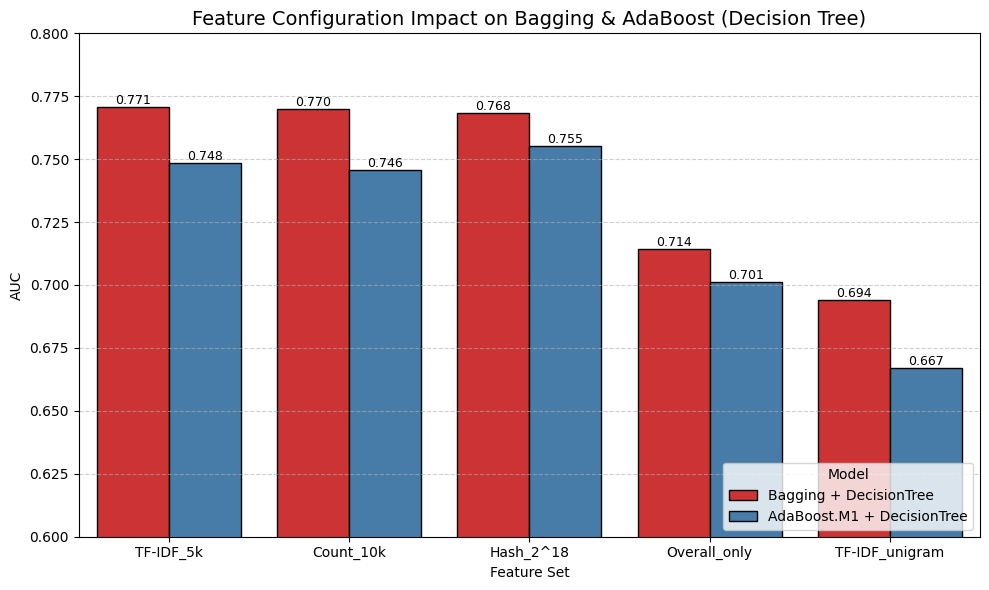

In [26]:
# best results ， visualization results
order = df_feat[df_feat['Model'] == 'Bagging + DecisionTree'].sort_values('AUC', ascending=False)['Feature']

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_feat,
    x='Feature', y='AUC', hue='Model',
    order=order,
    palette='Set1', edgecolor='black'
)

plt.title('Feature Configuration Impact on Bagging & AdaBoost (Decision Tree)', fontsize=14)
plt.ylabel('AUC')
plt.xlabel('Feature Set')
plt.ylim(0.6, 0.80)  # Implementation note
plt.legend(title='Model', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.6)

# value
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.savefig('feature_comparison.png', dpi=150)
plt.show()

### Experiment notes — 60

Interpretation of results and model behavior. Interpret the reported empirical results. Key techniques: Bagging, AdaBoost, AUC.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 61

Interpretation of results and model behavior. Key techniques: Bagging.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [10]:
# split training set and validation set
X_train_main, X_val, y_train_main, y_val = train_test_split(
    X_train, y_train, test_size=val_size, random_state=RANDOM_SEED, stratify=y_train
    )

print(f"训练集大小: {X_train_main.shape[0]}, 验证集大小: {X_val.shape[0]}")

训练集大小: 45631, 验证集大小: 11408


In [17]:
# ========== Bagging parameters ==========
bagging_params = {
    'n_estimators': [5, 10, 20, 50, 100],
    'max_samples': [0.3, 0.5, 0.7, 1.0],
    'max_depth': [3, 5, 10, None]
}

# Implementation note
def make_dt_base(max_depth):
    return DecisionTreeClassifier(max_depth=max_depth, random_state=RANDOM_SEED)

# value （ parameters parameters
bagging_defaults = {'n_estimators': 10, 'max_samples': 1.0, 'max_depth': 10}

In [11]:
bagging_results = []

# for parameters ， each parameters ， parameters for
for param_name, param_values in bagging_params.items():
    for val in param_values:
        # parameters
        params = bagging_defaults.copy()
        params[param_name] = val
        
        model = ManualBaggingClassifier(
            base_estimator=make_dt_base(params['max_depth']),
            n_estimators=params['n_estimators'],
            max_samples=params['max_samples'],
            n_jobs=-1,
            random_state=RANDOM_SEED
        )
        model.fit(X_train_main, y_train_main)
        y_proba = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_proba)
        bagging_results.append({
            'Parameter': param_name,
            'Value': val,
            'AUC': auc,
            'n_estimators': params['n_estimators'],
            'max_samples': params['max_samples'],
            'max_depth': params['max_depth']
        })
        print(f"Bagging | {param_name}={val} | Val AUC: {auc:.4f}")

df_bag = pd.DataFrame(bagging_results)
df_bag

Bagging | n_estimators=5 | Val AUC: 0.7618
Bagging | n_estimators=10 | Val AUC: 0.7675
Bagging | n_estimators=20 | Val AUC: 0.7708
Bagging | n_estimators=50 | Val AUC: 0.7729
Bagging | n_estimators=100 | Val AUC: 0.7746
Bagging | max_samples=0.3 | Val AUC: 0.7663
Bagging | max_samples=0.5 | Val AUC: 0.7683
Bagging | max_samples=0.7 | Val AUC: 0.7689
Bagging | max_samples=1.0 | Val AUC: 0.7675
Bagging | max_depth=3 | Val AUC: 0.7443
Bagging | max_depth=5 | Val AUC: 0.7612
Bagging | max_depth=10 | Val AUC: 0.7675
Bagging | max_depth=None | Val AUC: 0.7413


,Parameter,Value,AUC,n_estimators,max_samples,max_depth
0,n_estimators,5.0,0.761770,5,1.0,10.0
1,n_estimators,10.0,0.767506,10,1.0,10.0
2,n_estimators,20.0,0.770760,20,1.0,10.0
3,n_estimators,50.0,0.772858,50,1.0,10.0
4,n_estimators,100.0,0.774561,100,1.0,10.0
5,max_samples,0.3,0.766250,10,0.3,10.0
6,max_samples,0.5,0.768303,10,0.5,10.0
7,max_samples,0.7,0.768931,10,0.7,10.0
8,max_samples,1.0,0.767506,10,1.0,10.0
9,max_depth,3.0,0.744348,10,1.0,3.0


In [14]:
# results
df_bag.to_csv('bagging_para_results.csv', index=False)

In [12]:
bagging_best = {}
for param in bagging_params.keys():
    subset = df_bag[df_bag['Parameter'] == param]
    best_row = subset.loc[subset['AUC'].idxmax()]
    bagging_best[param] = best_row['Value']
print("Bagging best params:", bagging_best)

Bagging best params: {'n_estimators': 100.0, 'max_samples': 0.7, 'max_depth': 10.0}


In [29]:
import gc
gc.collect()

41961

### Experiment notes — 68

Review the implementation and results for this stage of the experiment. Key techniques: AdaBoost.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [14]:
# feature process
hash_vec = build_text_processor(method='hash', n_features=2**18, ngram_range=(1,2))
X_train_ada, X_test_ada = prepare_features(train_df, test_df, vectorizer=hash_vec, use_overall=True)

# split training set and validation set
X_train_main, X_val, y_train_main, y_val = train_test_split(
    X_train_ada, y_train, test_size=val_size, random_state=RANDOM_SEED, stratify=y_train
    )

print(f"特征处理：Hash_2^18 + Overall，训练集大小: {X_train_main.shape[0]}, 验证集大小: {X_val.shape[0]}")

特征处理：Hash_2^18 + Overall，训练集大小: 45631, 验证集大小: 11408


In [16]:
# ========== AdaBoost parameters ==========
adaboost_params = {
    'n_estimators': [10, 20, 50, 100],
    'learning_rate': [0.1, 0.3, 0.5, 0.8, 1.0, 1.5],
    'max_depth': [1, 2, 3, 5, 10]
}
adaboost_defaults = {'n_estimators': 10, 'learning_rate': 0.8, 'max_depth': 1}

# Implementation note
def make_dt_base(max_depth):
    return DecisionTreeClassifier(max_depth=max_depth, random_state=RANDOM_SEED)


In [20]:
adaboost_results = []
for param_name, param_values in adaboost_params.items():
    for val in param_values:
        params = adaboost_defaults.copy()
        params[param_name] = val
        
        model = ManualAdaBoostM1Classifier(
            base_estimator=make_dt_base(params['max_depth']),
            n_estimators=params['n_estimators'],
            learning_rate=params['learning_rate'],
            n_jobs=-1,
            random_state=RANDOM_SEED
        )
        model.fit(X_train_main, y_train_main)
        y_proba = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_proba)
        adaboost_results.append({
            'Parameter': param_name,
            'Value': val,
            'AUC': auc,
            'n_estimators': params['n_estimators'],
            'learning_rate': params['learning_rate'],
            'max_depth': params['max_depth']
        })
        print(f"AdaBoost | {param_name}={val} | Val AUC: {auc:.4f}")

df_ada = pd.DataFrame(adaboost_results)
df_ada

AdaBoost | n_estimators=10 | Val AUC: 0.7551
AdaBoost | n_estimators=20 | Val AUC: 0.7636
AdaBoost | n_estimators=50 | Val AUC: 0.7696
AdaBoost | n_estimators=100 | Val AUC: 0.7722
AdaBoost | learning_rate=0.1 | Val AUC: 0.7551
AdaBoost | learning_rate=0.3 | Val AUC: 0.7551
AdaBoost | learning_rate=0.5 | Val AUC: 0.7551
AdaBoost | learning_rate=0.8 | Val AUC: 0.7551
AdaBoost | learning_rate=1.0 | Val AUC: 0.7551
AdaBoost | learning_rate=1.5 | Val AUC: 0.7551
AdaBoost | max_depth=1 | Val AUC: 0.7551
AdaBoost | max_depth=2 | Val AUC: 0.7563
AdaBoost | max_depth=3 | Val AUC: 0.7615
AdaBoost | max_depth=5 | Val AUC: 0.7685
AdaBoost | max_depth=10 | Val AUC: 0.7566


,Parameter,Value,AUC,n_estimators,learning_rate,max_depth
0,n_estimators,10.0,0.755105,10,0.8,1
1,n_estimators,20.0,0.763577,20,0.8,1
2,n_estimators,50.0,0.769557,50,0.8,1
3,n_estimators,100.0,0.772215,100,0.8,1
4,learning_rate,0.1,0.755105,10,0.1,1
5,learning_rate,0.3,0.755105,10,0.3,1
6,learning_rate,0.5,0.755105,10,0.5,1
7,learning_rate,0.8,0.755105,10,0.8,1
8,learning_rate,1.0,0.755105,10,1.0,1
9,learning_rate,1.5,0.755105,10,1.5,1


In [21]:
adaboost_best = {}
for param in adaboost_params.keys():
    subset = df_ada[df_ada['Parameter'] == param]
    best_row = subset.loc[subset['AUC'].idxmax()]
    adaboost_best[param] = best_row['Value']
print("AdaBoost best params:", adaboost_best)

AdaBoost best params: {'n_estimators': 100.0, 'learning_rate': 0.1, 'max_depth': 5.0}


In [22]:
# results
df_ada.to_csv('adaboost_para_results.csv', index=False)

### Experiment notes — 74

Evaluate out-of-sample predictions. Visualize model performance and data distributions.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [11]:
# load results
df_bag = pd.read_csv('bagging_para_results.csv')
df_ada = pd.read_csv('adaboost_para_results.csv')

bagging_best = {'n_estimators': 100.0, 'max_samples': 0.7, 'max_depth': 10.0}
adaboost_best = {'n_estimators': 100.0, 'learning_rate': 0.1, 'max_depth': 5.0}

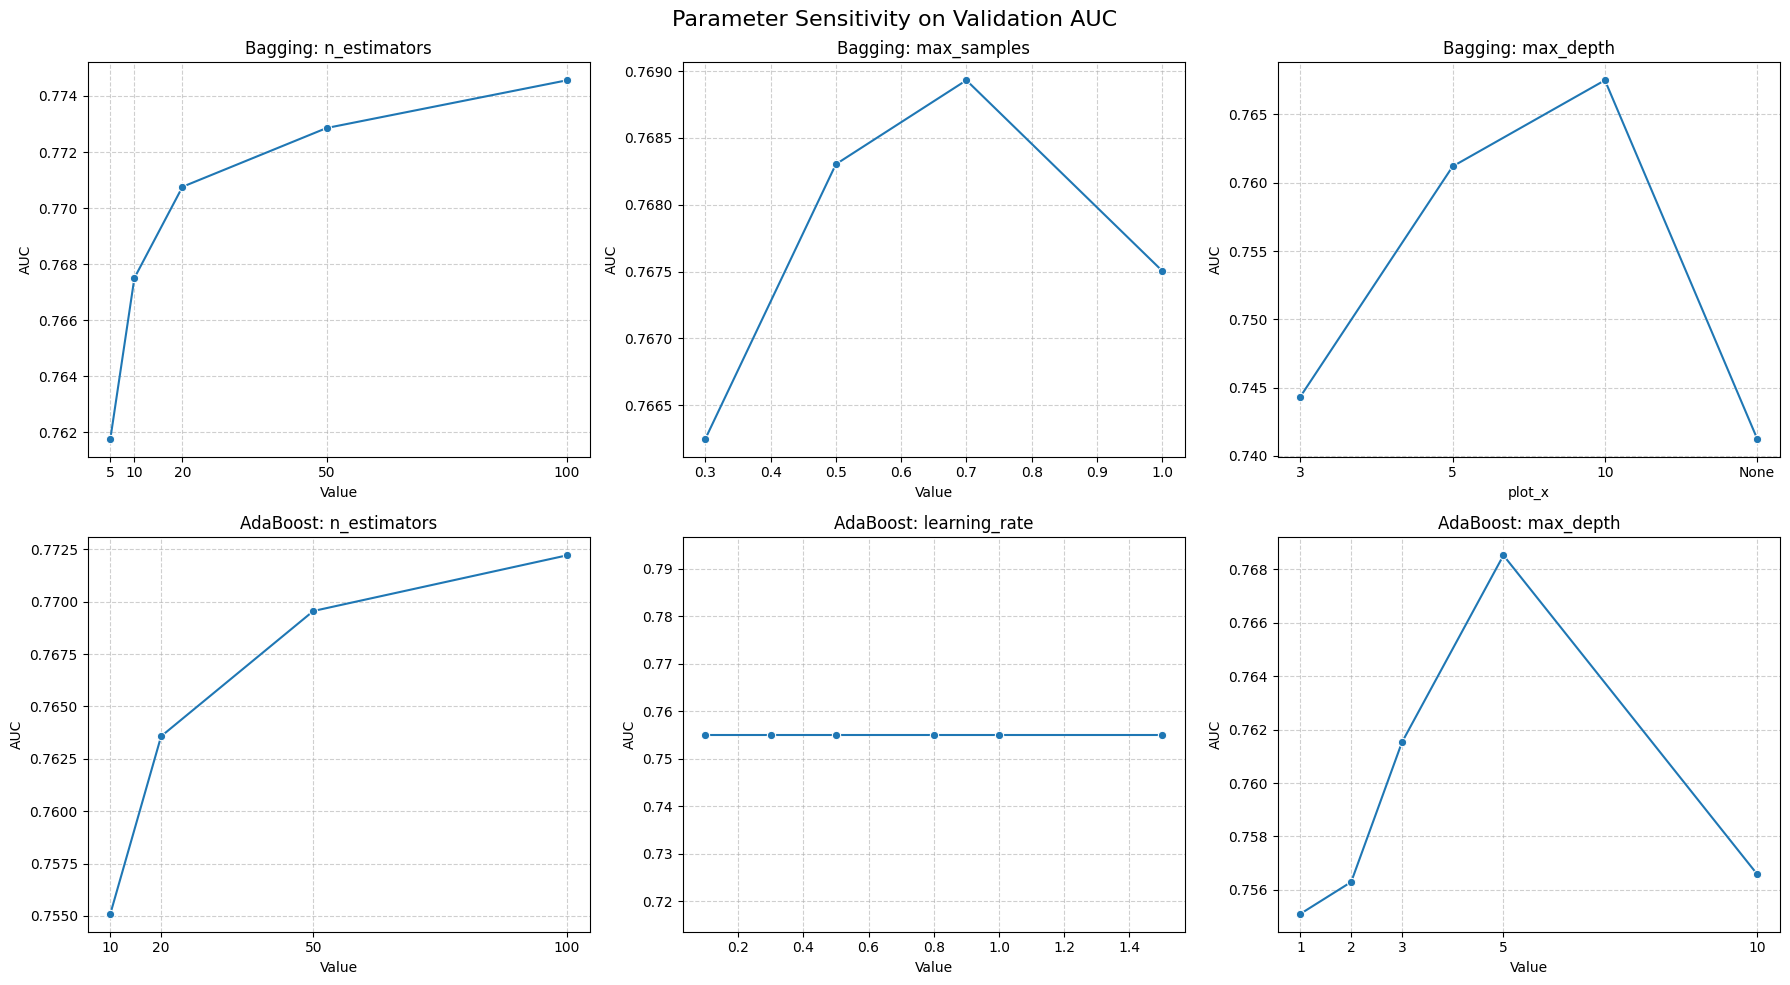

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Bagging
# Bagging data process None value
df_bag['plot_x'] = df_bag.apply(
    lambda row: str(int(row['Value'])) if row['Parameter'] != 'max_depth' 
                else (str(int(row['Value'])) if pd.notna(row['Value']) else 'None'),
    axis=1
)
        
for i, param in enumerate(bagging_params.keys()):
    ax = axes[0, i]
    data = df_bag[df_bag['Parameter'] == param]
    
    # max_depth， display
    if param == 'max_depth':
        order = ['3', '5', '10', 'None']
        sns.lineplot(data=data, x='plot_x', y='AUC', marker='o', ax=ax, sort=False)
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order)
    else:
        sns.lineplot(data=data, x='Value', y='AUC', marker='o', ax=ax)
        if param == 'n_estimators':
            ax.set_xticks([5, 10, 20, 50, 100])
    
    ax.set_title(f'Bagging: {param}')
    ax.grid(True, linestyle='--', alpha=0.6)
    
     
# AdaBoost
for i, param in enumerate(adaboost_params.keys()):
    ax = axes[1, i]
    data = df_ada[df_ada['Parameter'] == param]
    sns.lineplot(data=data, x='Value', y='AUC', marker='o', ax=ax)
    ax.set_title(f'AdaBoost: {param}')
    ax.grid(True, linestyle='--', alpha=0.6)
    if param == 'n_estimators':
        ax.set_xticks([10, 20, 50, 100])
    if param == 'max_depth':
        ax.set_xticks([1,2,3,5,10])

# plot
# if len(bagging_params) < 3:
#     for j in range(len(bagging_params), 3):
#         axes[0, j].axis('off')
# if len(adaboost_params) < 3:
#     for j in range(len(adaboost_params), 3):
#         axes[1, j].axis('off')

plt.suptitle('Parameter Sensitivity on Validation AUC', fontsize=16)
plt.tight_layout()
plt.savefig('param_sensitivity.png', dpi=150)
plt.show()

### Experiment notes — 77

Evaluate a held-out test split.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [34]:
print("="*50)
print("最佳参数：\n")
print(f"Bagging + DecisionTree (特征空间：TF-IDF + Overall)：{bagging_best}")
print(f"AdaBoostM1 + DecisionTree (特征空间：Hash_2^18 + Overall)：{adaboost_best}")

最佳参数：

Bagging + DecisionTree (特征空间：TF-IDF + Overall)：{'n_estimators': 100.0, 'max_samples': 0.7, 'max_depth': 10.0}
AdaBoostM1 + DecisionTree (特征空间：Hash_2^18 + Overall)：{'n_estimators': 100.0, 'learning_rate': 0.1, 'max_depth': 5.0}


In [31]:
# again training optimal model （ use training data X_train, y_train
print("开始训练最佳参数 Bagging + DecisionTree 模型...")
bagging_best_model = ManualBaggingClassifier(
    base_estimator=make_dt_base(int(bagging_best['max_depth'])),
    n_estimators=int(bagging_best['n_estimators']),
    max_samples=float(bagging_best['max_samples']),
    n_jobs=-1,
    random_state=RANDOM_SEED
)
bagging_best_model.fit(X_train, y_train)
y_proba_bag_best = bagging_best_model.predict_proba(X_test)[:, 1]
bagging_best_auc = roc_auc_score(y_test, y_proba_bag_best)

开始训练最佳参数 Bagging + DecisionTree 模型...


In [32]:
# feature process
hash_vec = build_text_processor(method='hash', n_features=2**18, ngram_range=(1,2))
X_train_ada, X_test_ada = prepare_features(train_df, test_df, vectorizer=hash_vec, use_overall=True)

print("开始训练最佳参数 AdaBoost + DecisionTree 模型 (hash)...")
adaboost_best_model = ManualAdaBoostM1Classifier(
    base_estimator=make_dt_base(int(adaboost_best['max_depth'])),
    n_estimators=int(adaboost_best['n_estimators']),
    learning_rate=float(adaboost_best['learning_rate']),
    n_jobs=-1,
    random_state=RANDOM_SEED
)
adaboost_best_model.fit(X_train_ada, y_train)
y_proba_ada_best = adaboost_best_model.predict_proba(X_test_ada)[:, 1]
adaboost_best_auc = roc_auc_score(y_test, y_proba_ada_best)

开始训练最佳参数 AdaBoost + DecisionTree 模型 (hash)...


In [33]:
# and parameters results comparison
bagging_default_auc = 0.7709  
adaboost_default_auc = 0.7483 

print("\n===== Test Set AUC Comparison =====")
print(f"Bagging Default: {bagging_default_auc:.4f} → Optimized: {bagging_best_auc:.4f}")
print(f"AdaBoost Default: {adaboost_default_auc:.4f} → Optimized: {adaboost_best_auc:.4f}")


===== Test Set AUC Comparison =====
Bagging Default: 0.7709 → Optimized: 0.7766
AdaBoost Default: 0.7483 → Optimized: 0.7778


### Experiment notes — 82

Interpretation of results and model behavior. Interpret the reported empirical results. Key techniques: Bagging, AdaBoost.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*